In [1]:

from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch
import torchvision

# Project setup
PROJECT_ROOT = Path.home() / "Documents" / "CervicalCancerProject"
DATA_DIR = PROJECT_ROOT / "data" / "SIPaKMeD"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
RESULTS_DIR = PROJECT_ROOT / "results"

# Preserve existing work
for folder in [CHECKPOINT_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PROJECT ROOT:", PROJECT_ROOT)
print("Project exists:", PROJECT_ROOT.exists())
print("Dataset path:", DATA_DIR)
print("Dataset exists:", DATA_DIR.exists())
print("Checkpoints folder:", CHECKPOINT_DIR.exists())
print("Results folder:", RESULTS_DIR.exists())
print("\nPyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())


PROJECT ROOT: /Users/harleendhillon/Documents/CervicalCancerProject
Project exists: True
Dataset path: /Users/harleendhillon/Documents/CervicalCancerProject/data/SIPaKMeD
Dataset exists: True
Checkpoints folder: True
Results folder: True

PyTorch: 2.14.1
Torchvision: 0.29.1
MPS available: True
CUDA available: False


Inspect the dataset

In [2]:

from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("Dataset directory:", DATA_DIR.resolve())
print("\nTop-level contents:")

for item in sorted(DATA_DIR.iterdir()):
    print(f"{'[DIR] ' if item.is_dir() else '[FILE]'} {item.name}")

print("\nImage counts by folder:")

total_images = 0

for folder in sorted(DATA_DIR.rglob("*")):
    if not folder.is_dir():
        continue

    images = sum(
        1 for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    )

    if images:
        print(f"{folder.name}: {images}")
        total_images += images

print("\nTotal images counted across folders:", total_images)


Dataset directory: /Users/harleendhillon/Downloads/archive

Top-level contents:
[FILE] .DS_Store
[DIR]  im_Dyskeratotic
[DIR]  im_Koilocytotic
[DIR]  im_Metaplastic
[DIR]  im_Parabasal
[DIR]  im_Superficial-Intermediate

Image counts by folder:
im_Dyskeratotic: 223
CROPPED: 813
im_Koilocytotic: 238
CROPPED: 825
im_Metaplastic: 271
CROPPED: 793
im_Parabasal: 108
CROPPED: 787
im_Superficial-Intermediate: 126
CROPPED: 831

Total images counted across folders: 5015


In [3]:

from pathlib import Path

DATA_DIR = Path.home() / "Downloads" / "archive"

for class_dir in sorted(DATA_DIR.iterdir()):
    if not class_dir.is_dir() or class_dir.name == ".DS_Store":
        continue

    cropped_dir = class_dir / "CROPPED"

    print(f"\n{'=' * 55}")
    print("CLASS:", class_dir.name)

    direct_images = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    print("Direct image examples:")
    for p in sorted(direct_images)[:5]:
        print(" ", p.name)

    print("\nCROPPED folder exists:", cropped_dir.exists())

    if cropped_dir.exists():
        cropped_images = [
            p for p in cropped_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ]

        print("Cropped image examples:")
        for p in sorted(cropped_images)[:5]:
            print(" ", p.name)



CLASS: im_Dyskeratotic
Direct image examples:

CROPPED folder exists: False

CLASS: im_Koilocytotic
Direct image examples:

CROPPED folder exists: False

CLASS: im_Metaplastic
Direct image examples:

CROPPED folder exists: False

CLASS: im_Parabasal
Direct image examples:

CROPPED folder exists: False

CLASS: im_Superficial-Intermediate
Direct image examples:

CROPPED folder exists: False


In [4]:

from pathlib import Path

DATA_DIR = Path.home() / "Downloads" / "archive"

for class_dir in sorted(DATA_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    print(f"\n{'=' * 55}")
    print("CLASS FOLDER:", class_dir.name)

    # Find every directory named CROPPED inside this class
    cropped_dirs = [
        p for p in class_dir.rglob("*")
        if p.is_dir() and p.name.lower() == "cropped"
    ]

    print("CROPPED directories found:", len(cropped_dirs))

    for cropped_dir in cropped_dirs:
        print("Path:", cropped_dir)
        examples = [
            p for p in cropped_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ]
        print("Images directly inside:", len(examples))
        print("Examples:", [p.name for p in sorted(examples)[:3]])

    # Show immediate subdirectories too
    print("Immediate subdirectories:")
    for subdir in sorted(class_dir.iterdir()):
        if subdir.is_dir():
            print(" ", subdir.name)



CLASS FOLDER: im_Dyskeratotic
CROPPED directories found: 1
Path: /Users/harleendhillon/Downloads/archive/im_Dyskeratotic/im_Dyskeratotic/CROPPED
Images directly inside: 813
Examples: ['001_01.bmp', '001_02.bmp', '001_03.bmp']
Immediate subdirectories:
  im_Dyskeratotic

CLASS FOLDER: im_Koilocytotic
CROPPED directories found: 1
Path: /Users/harleendhillon/Downloads/archive/im_Koilocytotic/im_Koilocytotic/CROPPED
Images directly inside: 825
Examples: ['001_01.bmp', '002_01.bmp', '003_01.bmp']
Immediate subdirectories:
  im_Koilocytotic

CLASS FOLDER: im_Metaplastic
CROPPED directories found: 1
Path: /Users/harleendhillon/Downloads/archive/im_Metaplastic/im_Metaplastic/CROPPED
Images directly inside: 793
Examples: ['001_01.bmp', '001_02.bmp', '001_03.bmp']
Immediate subdirectories:
  im_Metaplastic

CLASS FOLDER: im_Parabasal
CROPPED directories found: 1
Path: /Users/harleendhillon/Downloads/archive/im_Parabasal/im_Parabasal/CROPPED
Images directly inside: 787
Examples: ['001_01.bmp', '

Create the dataset manifest
A manifest is a table containing each image's path, class label and filename. It won't move or modify any images.

In [5]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path.home() / "Downloads" / "archive"

CLASS_NAMES = {
    "im_Dyskeratotic": "Dyskeratotic",
    "im_Koilocytotic": "Koilocytotic",
    "im_Metaplastic": "Metaplastic",
    "im_Parabasal": "Parabasal",
    "im_Superficial-Intermediate": "Superficial-Intermediate",
}

IMAGE_EXTENSIONS = {".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff"}

records = []

for folder_name, class_name in CLASS_NAMES.items():
    cropped_dir = (
        DATA_DIR
        / folder_name
        / folder_name
        / "CROPPED"
    )

    if not cropped_dir.is_dir():
        raise FileNotFoundError(
            f"Missing cropped folder: {cropped_dir}"
        )

    for image_path in sorted(cropped_dir.iterdir()):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "image_path": str(image_path.resolve()),
                "filename": image_path.name,
                "class_name": class_name,
                "class_folder": folder_name,
            })

manifest = pd.DataFrame(records)

print("Total images:", len(manifest))
print("\nImages per class:")
print(manifest["class_name"].value_counts().sort_index())

print("\nMissing image paths:", 
      sum(not Path(p).is_file() for p in manifest["image_path"]))

print("\nDuplicate paths:", manifest["image_path"].duplicated().sum())

display(manifest.head())


Total images: 4049

Images per class:
class_name
Dyskeratotic                813
Koilocytotic                825
Metaplastic                 793
Parabasal                   787
Superficial-Intermediate    831
Name: count, dtype: int64

Missing image paths: 0

Duplicate paths: 0


,image_path,filename,class_name,class_folder
0,/Users/harleendhillon/Downloads/archive/im_Dys...,001_01.bmp,Dyskeratotic,im_Dyskeratotic
1,/Users/harleendhillon/Downloads/archive/im_Dys...,001_02.bmp,Dyskeratotic,im_Dyskeratotic
2,/Users/harleendhillon/Downloads/archive/im_Dys...,001_03.bmp,Dyskeratotic,im_Dyskeratotic
3,/Users/harleendhillon/Downloads/archive/im_Dys...,001_04.bmp,Dyskeratotic,im_Dyskeratotic
4,/Users/harleendhillon/Downloads/archive/im_Dys...,001_05.bmp,Dyskeratotic,im_Dyskeratotic


Investigate image groups

In [6]:

# Extract possible source-image ID from each filename
# Example: 001_03.bmp -> 001

manifest["source_id"] = manifest["filename"].apply(
    lambda name: Path(name).stem.split("_")[0]
)

# Combine class and source ID to avoid collisions
# between different classes
manifest["group_id"] = (
    manifest["class_name"] + "_" + manifest["source_id"]
)

print("Total images:", len(manifest))
print("Unique image groups:", manifest["group_id"].nunique())

print("\nGroups per class:")
print(
    manifest.groupby("class_name")["group_id"]
    .nunique()
)

print("\nImages per group (summary):")
print(
    manifest.groupby("group_id")
    .size()
    .describe()
)

print("\nExample related images:")
display(
    manifest[
        manifest["group_id"] == "Dyskeratotic_001"
    ][["filename", "class_name", "group_id"]].head(10)
)


Total images: 4049
Unique image groups: 966

Groups per class:
class_name
Dyskeratotic                223
Koilocytotic                238
Metaplastic                 271
Parabasal                   108
Superficial-Intermediate    126
Name: group_id, dtype: int64

Images per group (summary):
count    966.000000
mean       4.191511
std        3.699261
min        1.000000
25%        1.000000
50%        3.000000
75%        6.000000
max       26.000000
dtype: float64

Example related images:


,filename,class_name,group_id
0,001_01.bmp,Dyskeratotic,Dyskeratotic_001
1,001_02.bmp,Dyskeratotic,Dyskeratotic_001
2,001_03.bmp,Dyskeratotic,Dyskeratotic_001
3,001_04.bmp,Dyskeratotic,Dyskeratotic_001
4,001_05.bmp,Dyskeratotic,Dyskeratotic_001


Inspect the grouping pattern

In [7]:

# Inspect groups containing multiple images
group_sizes = manifest.groupby("group_id").size()

multi_image_groups = group_sizes[group_sizes > 1]

print("Groups with multiple images:", len(multi_image_groups))
print("Groups with only one image:", (group_sizes == 1).sum())

print("\nLargest groups:")
display(
    group_sizes.sort_values(ascending=False)
    .head(10)
    .rename("image_count")
    .to_frame()
)

print("\nExample filenames from selected groups:")
for group_id in [
    "Dyskeratotic_001",
    "Koilocytotic_001",
    "Metaplastic_001",
]:
    rows = manifest.loc[
        manifest["group_id"] == group_id,
        ["filename", "class_name", "group_id"]
    ]

    print(f"\n{group_id}: {len(rows)} images")
    display(rows.head(10))


Groups with multiple images: 722
Groups with only one image: 244

Largest groups:


,image_count
group_id,
Parabasal_093,26
Koilocytotic_105,25
Dyskeratotic_164,24
Superficial-Intermediate_017,22
Dyskeratotic_067,21
Koilocytotic_095,19
Parabasal_095,17
Parabasal_100,17
Koilocytotic_122,16



Example filenames from selected groups:

Dyskeratotic_001: 5 images


,filename,class_name,group_id
0,001_01.bmp,Dyskeratotic,Dyskeratotic_001
1,001_02.bmp,Dyskeratotic,Dyskeratotic_001
2,001_03.bmp,Dyskeratotic,Dyskeratotic_001
3,001_04.bmp,Dyskeratotic,Dyskeratotic_001
4,001_05.bmp,Dyskeratotic,Dyskeratotic_001



Koilocytotic_001: 1 images


,filename,class_name,group_id
813,001_01.bmp,Koilocytotic,Koilocytotic_001



Metaplastic_001: 13 images


,filename,class_name,group_id
1638,001_01.bmp,Metaplastic,Metaplastic_001
1639,001_02.bmp,Metaplastic,Metaplastic_001
1640,001_03.bmp,Metaplastic,Metaplastic_001
1641,001_04.bmp,Metaplastic,Metaplastic_001
1642,001_05.bmp,Metaplastic,Metaplastic_001
1643,001_06.bmp,Metaplastic,Metaplastic_001
1644,001_07.bmp,Metaplastic,Metaplastic_001
1645,001_08.bmp,Metaplastic,Metaplastic_001
1646,001_09.bmp,Metaplastic,Metaplastic_001
1647,001_10.bmp,Metaplastic,Metaplastic_001


Visualize sample images

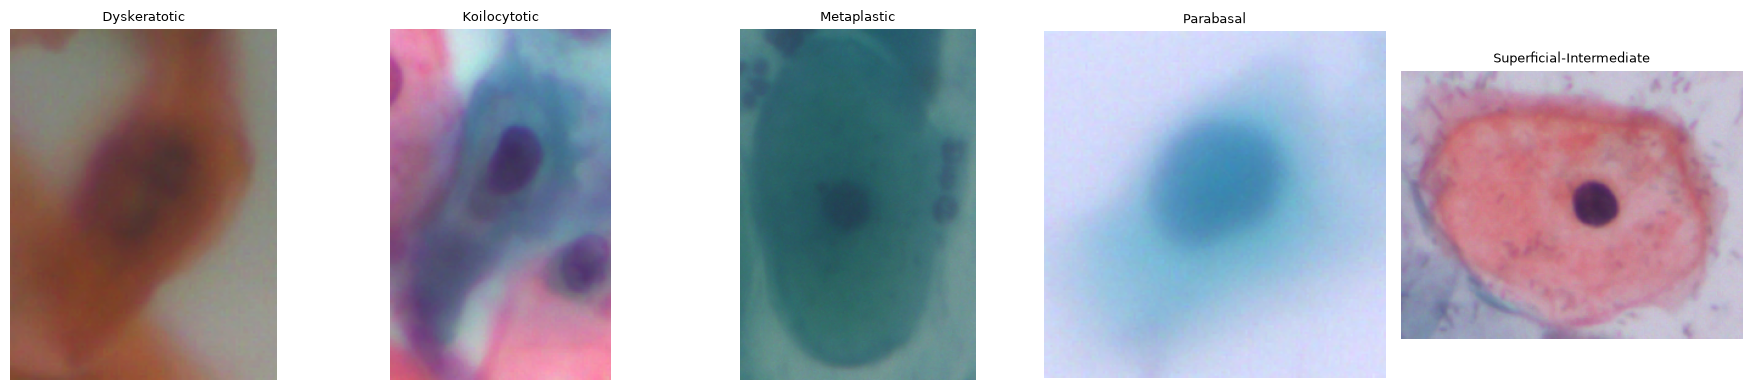

In [8]:

import matplotlib.pyplot as plt
from PIL import Image

# One random sample from each class
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, class_name in zip(axes, CLASS_NAMES.values()):
    samples = manifest.loc[
        manifest["class_name"] == class_name
    ]

    sample = samples.sample(n=1, random_state=SEED).iloc[0]

    with Image.open(sample["image_path"]) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(class_name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


Check image quality and dimensions

In [9]:

from PIL import Image
from pathlib import Path
import numpy as np
import pandas as pd

def inspect_image(path):
    try:
        with Image.open(path) as img:
            img.load()
            gray = np.asarray(img.convert("L"), dtype=np.float32)

            # Simple sharpness indicator; higher often means sharper
            laplacian = (
                -4 * gray
                + np.roll(gray, 1, axis=0)
                + np.roll(gray, -1, axis=0)
                + np.roll(gray, 1, axis=1)
                + np.roll(gray, -1, axis=1)
            )

            return {
                "width": img.width,
                "height": img.height,
                "sharpness_score": float(laplacian.var()),
                "readable": True,
            }
    except Exception:
        return {
            "width": None,
            "height": None,
            "sharpness_score": None,
            "readable": False,
        }

# Inspect every image
quality_records = []

for row in manifest.itertuples(index=False):
    result = inspect_image(row.image_path)
    quality_records.append({
        "image_path": row.image_path,
        "filename": row.filename,
        "class_name": row.class_name,
        **result,
    })

quality_df = pd.DataFrame(quality_records)

print("Total inspected:", len(quality_df))
print("Unreadable images:", (~quality_df["readable"]).sum())

print("\nImage dimensions:")
display(
    quality_df.groupby(["width", "height"])
    .size()
    .rename("count")
    .reset_index()
    .sort_values("count", ascending=False)
    .head(10)
)

print("\nSharpness summary by class:")
display(
    quality_df.groupby("class_name")["sharpness_score"]
    .agg(["median", "mean", "min", "max"])
    .round(2)
)


Total inspected: 4049
Unreadable images: 0

Image dimensions:


,width,height,count
702,126,104,3
236,96,98,3
218,95,86,3
1259,156,148,3
559,118,93,3
1149,150,148,3
1101,148,108,3
1940,195,166,3
1113,148,143,3
688,125,109,3



Sharpness summary by class:


,median,mean,min,max
class_name,,,,
Dyskeratotic,71.21,106.28,12.06,825.21
Koilocytotic,105.03,121.13,19.39,461.62
Metaplastic,65.94,80.74,13.07,470.57
Parabasal,40.03,48.46,13.20,277.55
Superficial-Intermediate,46.87,51.03,15.50,147.51


Check whether image groups are balanced across classes

In [10]:

# Inspect the number of images per candidate group in each class

group_summary = (
    manifest.groupby(["class_name", "group_id"])
    .size()
    .rename("images_per_group")
    .reset_index()
)

print("Groups and image counts by class:")
display(
    group_summary.groupby("class_name")["images_per_group"]
    .agg(
        groups="count",
        min_images="min",
        median_images="median",
        max_images="max",
    )
    .astype(int)
)

print("\nExample groups from each class:")
for class_name in CLASS_NAMES.values():
    print(f"\n{class_name}")
    display(
        group_summary[group_summary["class_name"] == class_name]
        .sort_values("group_id")
        .head(5)
    )


Groups and image counts by class:


,groups,min_images,median_images,max_images
class_name,,,,
Dyskeratotic,223,1,2,24
Koilocytotic,238,1,2,25
Metaplastic,271,1,2,15
Parabasal,108,1,7,26
Superficial-Intermediate,126,1,6,22



Example groups from each class:

Dyskeratotic


,class_name,group_id,images_per_group
0,Dyskeratotic,Dyskeratotic_001,5
1,Dyskeratotic,Dyskeratotic_002,10
2,Dyskeratotic,Dyskeratotic_003,12
3,Dyskeratotic,Dyskeratotic_004,3
4,Dyskeratotic,Dyskeratotic_005,7



Koilocytotic


...

,class_name,group_id,images_per_group
461,Metaplastic,Metaplastic_001,13
462,Metaplastic,Metaplastic_002,15
463,Metaplastic,Metaplastic_003,1
464,Metaplastic,Metaplastic_004,1
465,Metaplastic,Metaplastic_005,1



Parabasal


,class_name,group_id,images_per_group
732,Parabasal,Parabasal_001,13
733,Parabasal,Parabasal_002,4
734,Parabasal,Parabasal_003,13
735,Parabasal,Parabasal_004,13
736,Parabasal,Parabasal_005,6



Superficial-Intermediate


,class_name,group_id,images_per_group
840,Superficial-Intermediate,Superficial-Intermediate_001,5
841,Superficial-Intermediate,Superficial-Intermediate_002,6
842,Superficial-Intermediate,Superficial-Intermediate_003,3
843,Superficial-Intermediate,Superficial-Intermediate_004,13
844,Superficial-Intermediate,Superficial-Intermediate_005,5


Verify the original dataset structure

In [11]:

from pathlib import Path

DATA_DIR = Path.home() / "Downloads" / "archive"

for class_folder in sorted(DATA_DIR.iterdir()):
    if not class_folder.is_dir():
        continue

    print(f"\n{'=' * 50}")
    print(class_folder.name)

    for path in sorted(class_folder.iterdir()):
        if path.is_dir():
            print(f"\nFolder: {path.name}")

            for child in sorted(path.iterdir())[:8]:
                if child.is_dir():
                    print(f"  [DIR]  {child.name}")
                else:
                    print(f"  [FILE] {child.name}")



im_Dyskeratotic

Folder: im_Dyskeratotic
  [FILE] 001.bmp
  [FILE] 001_cyt01.dat
  [FILE] 001_cyt02.dat
  [FILE] 001_cyt03.dat
  [FILE] 001_cyt04.dat
  [FILE] 001_cyt05.dat
  [FILE] 001_nuc01.dat
  [FILE] 001_nuc02.dat

im_Koilocytotic

Folder: im_Koilocytotic
  [FILE] 001.bmp
  [FILE] 001_cyt01.dat
  [FILE] 001_nuc01.dat
  [FILE] 002.bmp
  [FILE] 002_cyt01.dat
  [FILE] 002_nuc01.dat
  [FILE] 003.bmp
  [FILE] 003_cyt01.dat

im_Metaplastic

Folder: im_Metaplastic
  [FILE] 001.bmp
  [FILE] 001_cyt01.dat
  [FILE] 001_cyt02.dat
  [FILE] 001_cyt03.dat
  [FILE] 001_cyt04.dat
  [FILE] 001_cyt05.dat
  [FILE] 001_cyt06.dat
  [FILE] 001_cyt07.dat

im_Parabasal

Folder: im_Parabasal
  [FILE] 001.bmp
  [FILE] 001_cyt01.dat
  [FILE] 001_cyt02.dat
  [FILE] 001_cyt03.dat
  [FILE] 001_cyt04.dat
  [FILE] 001_cyt05.dat
  [FILE] 001_cyt06.dat
  [FILE] 001_cyt07.dat

im_Superficial-Intermediate

Folder: im_Superficial-Intermediate
  [FILE] 001.bmp
  [FILE] 001_cyt01.dat
  [FILE] 001_cyt02.dat
  [FILE] 00

In [12]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path.home() / "Downloads" / "archive"

for folder_name in CLASS_NAMES:
    source_dir = DATA_DIR / folder_name / folder_name
    cropped_dir = source_dir / "CROPPED"

    source_ids = {
        p.stem
        for p in source_dir.glob("*.bmp")
    }

    cropped_ids = {
        p.name.split("_")[0]
        for p in cropped_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    }

    print(f"\n{folder_name}")
    print("Original BMP images:", len(source_ids))
    print("Unique cropped filename prefixes:", len(cropped_ids))
    print("Prefixes matching original BMP IDs:",
          len(source_ids & cropped_ids))
    print("Example original IDs:", sorted(source_ids)[:5])
    print("Example cropped IDs:", sorted(cropped_ids)[:5])



im_Dyskeratotic
Original BMP images: 223
Unique cropped filename prefixes: 223
Prefixes matching original BMP IDs: 223
Example original IDs: ['001', '002', '003', '004', '005']
Example cropped IDs: ['001', '002', '003', '004', '005']

im_Koilocytotic
Original BMP images: 238
Unique cropped filename prefixes: 238
Prefixes matching original BMP IDs: 238
Example original IDs: ['001', '002', '003', '004', '005']
Example cropped IDs: ['001', '002', '003', '004', '005']

im_Metaplastic
Original BMP images: 271
Unique cropped filename prefixes: 271
Prefixes matching original BMP IDs: 271
Example original IDs: ['001', '002', '003', '004', '005']
Example cropped IDs: ['001', '002', '003', '004', '005']

im_Parabasal
Original BMP images: 108
Unique cropped filename prefixes: 108
Prefixes matching original BMP IDs: 108
Example original IDs: ['001', '002', '003', '004', '005']
Example cropped IDs: ['001', '002', '003', '004', '005']

im_Superficial-Intermediate
Original BMP images: 126
Unique cro

Create a group-aware train/validation/test split

In [13]:

from sklearn.model_selection import StratifiedGroupKFold
from pathlib import Path
import pandas as pd
import numpy as np

# Rebuild the grouping key from verified source IDs
manifest["source_id"] = manifest["filename"].apply(
    lambda name: Path(name).stem.split("_")[0]
)

manifest["group_id"] = (
    manifest["class_name"] + "_" + manifest["source_id"]
)

# Three approximately equal folds:
# 2 folds for train, 1 fold reserved for validation/test selection.
# We'll create a 70/15/15 split using two grouped holdouts.
outer_splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=SEED
)

# First: reserve approximately 20% for temporary holdout
train_val_idx, holdout_idx = next(
    outer_splitter.split(
        manifest,
        y=manifest["class_name"],
        groups=manifest["group_id"],
    )
)

train_val = manifest.iloc[train_val_idx].copy()
holdout = manifest.iloc[holdout_idx].copy()

# Divide the temporary holdout into validation and test groups
inner_splitter = StratifiedGroupKFold(
    n_splits=2, shuffle=True, random_state=SEED
)

val_rel_idx, test_rel_idx = next(
    inner_splitter.split(
        holdout,
        y=holdout["class_name"],
        groups=holdout["group_id"],
    )
)

validation = holdout.iloc[val_rel_idx].copy()
test = holdout.iloc[test_rel_idx].copy()

# Approximate 70/15/15 requires checking actual fold sizes;
# print the resulting split before deciding whether to adjust.
train = train_val

train["split"] = "train"
validation["split"] = "validation"
test["split"] = "test"

split_manifest = pd.concat(
    [train, validation, test],
    ignore_index=True
)

print("Split sizes:")
print(split_manifest["split"].value_counts())

print("\nClass distribution by split:")
display(pd.crosstab(
    split_manifest["split"],
    split_manifest["class_name"]
))

# Verify that no candidate group crosses splits
group_split_counts = (
    split_manifest.groupby("group_id")["split"].nunique()
)

print("\nGroups appearing in multiple splits:",
      int((group_split_counts > 1).sum()))

split_path = RESULTS_DIR / "sipakmed_group_split.csv"
split_manifest.to_csv(split_path, index=False)
print("\nSaved split manifest to:", split_path)


Split sizes:
split
train         3239
test           406
validation     404
Name: count, dtype: int64

Class distribution by split:


class_name,Dyskeratotic,Koilocytotic,Metaplastic,Parabasal,Superficial-Intermediate
split,,,,,
test,82,82,79,79,84
train,650,660,635,629,665
validation,81,83,79,79,82



Groups appearing in multiple splits: 0

Saved split manifest to: /Users/harleendhillon/Documents/CervicalCancerProject/results/sipakmed_group_split.csv


In [15]:

from sklearn.model_selection import GroupShuffleSplit
import pandas as pd
import numpy as np

# Use the already verified source-image grouping
df = manifest.copy()

df["source_id"] = df["filename"].apply(
    lambda name: Path(name).stem.split("_")[0]
)
df["group_id"] = df["class_name"] + "_" + df["source_id"]

# One row per source group, with its class label
groups_df = (
    df[["group_id", "class_name"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Split source groups, not individual cropped images
outer = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=SEED
)

train_group_idx, holdout_group_idx = next(
    outer.split(groups_df, groups=groups_df["group_id"])
)

train_groups = set(groups_df.iloc[train_group_idx]["group_id"])
holdout_groups = set(groups_df.iloc[holdout_group_idx]["group_id"])

# Split the holdout groups approximately 50/50
holdout_df = groups_df[
    groups_df["group_id"].isin(holdout_groups)
].reset_index(drop=True)

inner = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=SEED
)

val_idx, test_idx = next(
    inner.split(holdout_df, groups=holdout_df["group_id"])
)

val_groups = set(holdout_df.iloc[val_idx]["group_id"])
test_groups = set(holdout_df.iloc[test_idx]["group_id"])

# Assign each image to its source group's split
df["split"] = df["group_id"].map(
    lambda g: (
        "train" if g in train_groups
        else "validation" if g in val_groups
        else "test"
    )
)

split_manifest = df.copy()

print("Split sizes:")
print(split_manifest["split"].value_counts())
print("\nSplit percentages:")
print(
    (split_manifest["split"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nClass distribution:")
display(pd.crosstab(
    split_manifest["split"],
    split_manifest["class_name"]
))

# Leakage check
group_counts = split_manifest.groupby("group_id")["split"].nunique()
print("\nGroups crossing splits:", int((group_counts > 1).sum()))

split_path = RESULTS_DIR / "sipakmed_group_split.csv"
split_manifest.to_csv(split_path, index=False)
print("\nSaved:", split_path)


Split sizes:
split
train         2718
test           711
validation     620
Name: count, dtype: int64

Split percentages:
split
train         67.13
test          17.56
validation    15.31
Name: proportion, dtype: float64

Class distribution:


class_name,Dyskeratotic,Koilocytotic,Metaplastic,Parabasal,Superficial-Intermediate
split,,,,,
test,125,182,133,107,164
train,566,501,561,544,546
validation,122,142,99,136,121



Groups crossing splits: 0

Saved: /Users/harleendhillon/Documents/CervicalCancerProject/results/sipakmed_group_split.csv


Lock and verify the split

In [16]:

import pandas as pd
from pathlib import Path

split_path = RESULTS_DIR / "sipakmed_group_split.csv"
split_manifest = pd.read_csv(split_path)

# Basic integrity checks
assert len(split_manifest) == 4049, "Unexpected image count!"
assert split_manifest["image_path"].nunique() == 4049, "Duplicate paths!"
assert split_manifest["image_path"].map(
    lambda p: Path(p).is_file()
).all(), "Some image paths are missing!"

# Group leakage check
groups_per_split = (
    split_manifest.groupby("group_id")["split"].nunique()
)

assert (groups_per_split <= 1).all(), "Group leakage detected!"

# Confirm all classes exist in each partition
class_counts = pd.crosstab(
    split_manifest["split"],
    split_manifest["class_name"]
)

print("Integrity checks passed!")
print("\nSplit sizes:")
print(split_manifest["split"].value_counts())

print("\nClass counts:")
display(class_counts)

print("\nGroups crossing partitions:",
      int((groups_per_split > 1).sum()))


Integrity checks passed!

Split sizes:
split
train         2718
test           711
validation     620
Name: count, dtype: int64

Class counts:


class_name,Dyskeratotic,Koilocytotic,Metaplastic,Parabasal,Superficial-Intermediate
split,,,,,
test,125,182,133,107,164
train,566,501,561,544,546
validation,122,142,99,136,121



Groups crossing partitions: 0
